In [19]:
%run ../inspect_dataset.py

Dataset exists: True
Image directory exists: True
Mask directory exists: True

Images: 994
Masks: 996

Masks without image:
LIDC-IDRI-1002_R_1.nii.gz
LIDC-IDRI-1002_R_2.nii.gz

Images without mask:


In [6]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import sklearn
import nibabel as nib

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NiBabel:", nib.__version__)

Python: 3.15.0 (v3.15.0:d220409a13b, Oct  9 2026, 08:17:44) [Clang 21.0.0 (clang-2100.1.1.101)]
Python executable: /Users/omargutierrez/Luna Dataset Project/.venv/bin/python
NumPy: 2.5.4
Pandas: 3.0.6
Matplotlib: 3.11.2
Scikit-learn: 1.9.1
NiBabel: 5.4.2


In [7]:
from pathlib import Path

# Project root (notebook inside notebooks/)
PROJECT_ROOT = Path.cwd().parent

# Dataset location
DATASET_DIR = PROJECT_ROOT / "Description and Sample of the DataSet-20261006"

# Metadata
metadata_path = DATASET_DIR / "MetadatabyAnnotation.xlsx"

# Load Excel file
df = pd.read_excel(metadata_path)

print("Dataset dimensions:", df.shape)

display(df.head())

Dataset dimensions: (3674, 33)


,patient_id,nodule_id,seriesuid,coordX,coordY,coordZ,diameter_mm,bboxLowX,bboxLowY,bboxLowZ,...,Margin_value,Sphericity,Sphericity_value,Spiculation,Spiculation_value,Subtlety,Subtlety_value,Texture,Texture_value,len_mal_details
0,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,3,Ovoid,3,Near Marked Spiculation,4,Obvious,5,Solid,5,4
1,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,4,Ovoid/Round,4,Marked Spiculation,5,Obvious,5,Solid,5,4
2,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,2,Ovoid,3,Medium Spiculation,3,Obvious,5,Solid,5,4
3,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,4,Round,5,Marked Spiculation,5,Obvious,5,Solid/Mixed,4,4
4,LIDC-IDRI-0003,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...,72.286707,76.900239,-190.458928,21.453729,57.488893,63.984216,-199.0,...,3,Ovoid,3,Nearly No Spiculation,2,Obvious,5,Part Solid/Mixed,3,4


In [8]:
df.info

<bound method DataFrame.info of           patient_id  nodule_id  \
0     LIDC-IDRI-0001          1   
1     LIDC-IDRI-0001          1   
2     LIDC-IDRI-0001          1   
3     LIDC-IDRI-0001          1   
4     LIDC-IDRI-0003          2   
...              ...        ...   
3669  LIDC-IDRI-1011          2   
3670  LIDC-IDRI-1011          3   
3671  LIDC-IDRI-1011          3   
3672  LIDC-IDRI-1011          3   
3673  LIDC-IDRI-1011          3   

                                              seriesuid      coordX  \
0     1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...   56.208405   
1     1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...   56.208405   
2     1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...   56.208405   
3     1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...   56.208405   
4     1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...   72.286707   
...                                                 ...         ...   
3669  1.3.6.1.4.1.14519.5.2.1.6279.6001.2721233982

In [9]:
# Basic dataset statistics

print("Total annotations:", len(df))
print("Unique patients:", df["patient_id"].nunique())

nodule_cols = ["patient_id", "nodule_id"]

#Check how many patient we have
print(
    "Unique nodules:",
    df[nodule_cols].drop_duplicates().shape[0]
)

#Check if there is any missing value
print("\nMissing values:")
print(df.isnull().sum())


print("\nAnnotations per nodule:")
print(df.groupby(nodule_cols).size().value_counts().sort_index())

Total annotations: 3674
Unique patients: 551
Unique nodules: 996

Missing values:
patient_id                 0
nodule_id                  0
seriesuid                  0
coordX                     0
coordY                     0
coordZ                     0
diameter_mm                0
bboxLowX                   0
bboxLowY                   0
bboxLowZ                   0
bboxHighX                  0
bboxHighY                  0
bboxHighZ                  0
Malignancy                 0
Malignancy_value           0
anotation_id               0
Calcification              0
Calcification_value        0
InternalStructure          0
InternalStructure_value    0
Lobulation                 0
Lobulation_value           0
Margin                     0
Margin_value               0
Sphericity                 0
Sphericity_value           0
Spiculation                0
Spiculation_value          0
Subtlety                   0
Subtlety_value             0
Texture                    0
Texture_value      

In [10]:
# Create a nodule-level dataset

nodule_df = (
    df.groupby(["patient_id", "nodule_id"], as_index=False)
    .agg(
        diameter_mm=("diameter_mm", "median"),
        n_annotations=("anotation_id", "size"),
        min_diameter=("diameter_mm", "min"),
        max_diameter=("diameter_mm", "max")
    )
)

print("Number of unique nodules:", len(nodule_df))

display(nodule_df.head())

Number of unique nodules: 996


,patient_id,nodule_id,diameter_mm,n_annotations,min_diameter,max_diameter
0,LIDC-IDRI-0001,1,23.350644,4,23.350644,23.350644
1,LIDC-IDRI-0003,2,21.453729,4,21.453729,21.453729
2,LIDC-IDRI-0003,3,8.785833,4,8.785833,8.785833
3,LIDC-IDRI-0003,4,12.823120,4,12.823120,12.823120
4,LIDC-IDRI-0004,1,4.560710,4,4.560710,4.560710


Matplotlib is building the font cache; this may take a moment.


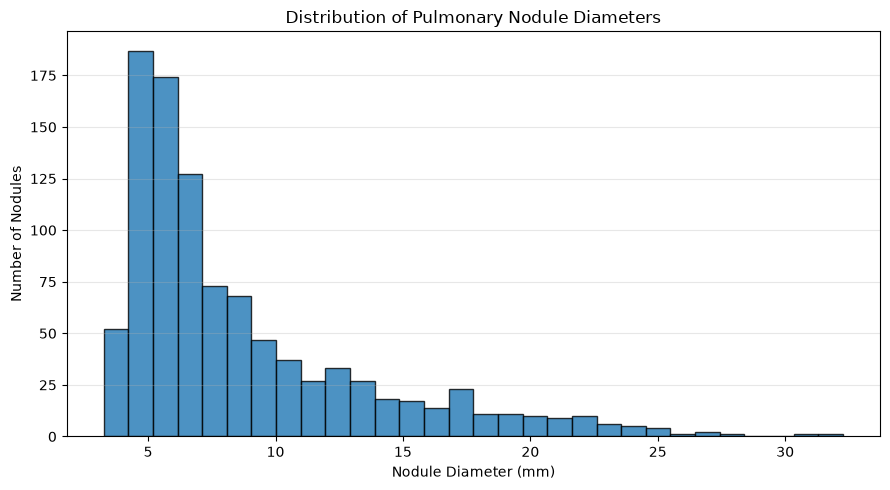

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    nodule_df["diameter_mm"],
    bins=30,
    edgecolor="black",
    alpha=0.8
)

plt.title("Distribution of Pulmonary Nodule Diameters")
plt.xlabel("Nodule Diameter (mm)")
plt.ylabel("Number of Nodules")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "results" / "nodule_diameter_distribution.png",
    dpi=300
)

plt.show()

In [12]:
nodule_df["diameter_difference"] = (
    nodule_df["max_diameter"] -
    nodule_df["min_diameter"]
)

print(nodule_df["diameter_mm"].describe())

print(
    "\nNodules with different diameter values:",
    (nodule_df["diameter_difference"] > 1e-6).sum()
)

display(
    nodule_df.sort_values(
        "diameter_difference",
        ascending=False
    ).head(10)
)

count    996.000000
mean       8.694826
std        4.939517
min        3.253443
25%        5.232312
50%        6.769231
75%       10.444362
max       32.270030
Name: diameter_mm, dtype: float64

Nodules with different diameter values: 1


,patient_id,nodule_id,diameter_mm,n_annotations,min_diameter,max_diameter,diameter_difference
400,LIDC-IDRI-0332,1,11.475523,9,11.475523,24.663360,13.187836
0,LIDC-IDRI-0001,1,23.350644,4,23.350644,23.350644,0.000000
668,LIDC-IDRI-0633,1,6.005399,4,6.005399,6.005399,0.000000
656,LIDC-IDRI-0615,1,5.738268,4,5.738268,5.738268,0.000000
657,LIDC-IDRI-0615,2,5.063187,4,5.063187,5.063187,0.000000
658,LIDC-IDRI-0617,2,11.475206,4,11.475206,11.475206,0.000000
659,LIDC-IDRI-0617,3,7.794844,4,7.794844,7.794844,0.000000
660,LIDC-IDRI-0619,1,10.572353,4,10.572353,10.572353,0.000000
661,LIDC-IDRI-0619,2,20.484109,4,20.484109,20.484109,0.000000
662,LIDC-IDRI-0620,1,8.103347,3,8.103347,8.103347,0.000000
